# TFLN

14:39:09 MDT WARNING: Use the remote mode solver with subpixel averaging for    
             better accuracy through 'tidy3d.web.run(...)' or the deprecated    
             'tidy3d.plugins.mode.web.run(...)'. Alternatively, you can install 
             the package 'tidy3d-extras' using 'pip install "tidy3d"' and set   
             'config.simulation.use_local_subpixel=True'.                       

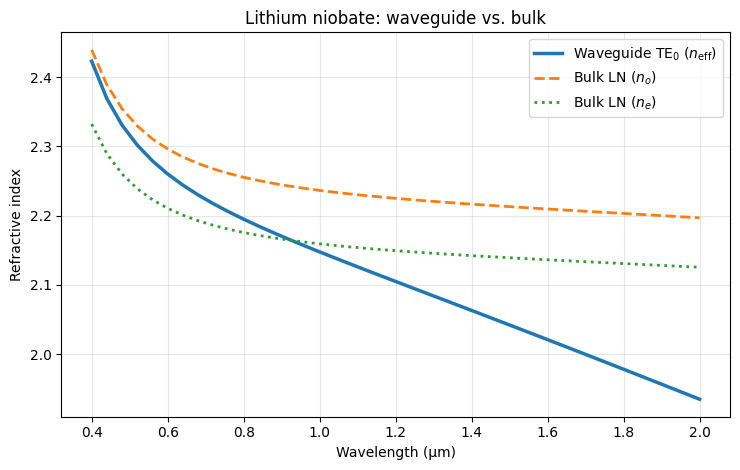

In [1]:

import numpy as np
import matplotlib.pyplot as plt
import tidy3d as td
from tidy3d.plugins.mode import ModeSolver

# --------------------------------------------------
# Parameters (all lengths in micrometers)
# --------------------------------------------------
width = 1.8
film_thickness = 0.7
etch_depth = 0.35
slab_thickness = film_thickness - etch_depth

wavelengths = np.linspace(0.4, 2.0, 41)
freqs = td.C_0 / wavelengths

# z-cut LN: optical axis is z.
# TE polarization is primarily Ey -> ordinary index.
ln = td.material_library["LiNbO3"]["Zelmon1997"](2)
sio2 = td.material_library["FusedSilica"]["ZemaxSellmeier"]

yspan, zspan = 8.0, 6.0


# Propagation: x
# Waveguide width: y
# Film thickness: z
film_bottom = -film_thickness / 2
slab_top = film_bottom + slab_thickness

# --------------------------------------------------
# Geometry
# --------------------------------------------------
substrate = td.Structure(
    geometry=td.Box(
        center=(0, 0, film_bottom - 2.0),
        size=(td.inf, td.inf, 4.0),
    ),
    medium=sio2,
)

slab = td.Structure(
    geometry=td.Box(
        center=(0, 0, (film_bottom + slab_top) / 2),
        size=(td.inf, td.inf, slab_thickness),
    ),
    medium=ln,
)

ridge = td.Structure(
    geometry=td.Box(
        center=(0, 0, slab_top + etch_depth / 2),
        size=(td.inf, width, etch_depth),
    ),
    medium=ln,
)

# --------------------------------------------------
# Simulation and mode solver
# --------------------------------------------------
yspan, zspan = 5.5, 4.0

sim = td.Simulation(
    size=(1.0, yspan, zspan),
    medium=td.Medium(permittivity=1.0),
    structures=[substrate, slab, ridge],
    grid_spec=td.GridSpec.auto(
        min_steps_per_wvl=20,
        wavelength=wavelengths.min(),
    ),
    boundary_spec=td.BoundarySpec.all_sides(
        boundary=td.PML()
    ),
    run_time=1e-12,
)

mode_solver = ModeSolver(
    simulation=sim,
    plane=td.Box(
        center=(0, 0, 0),
        size=(0, yspan, zspan),
    ),
    mode_spec = td.ModeSpec(
        num_modes=1,
        sort_spec=td.ModeSortSpec(
            sort_key="n_eff",
            track_freq=None,
        ),
    ),
    freqs=freqs,
)

# Run locally, without cloud credits.
mode_data = mode_solver.solve()

# Fundamental TE-like mode
n_eff = np.real(
    mode_data.n_eff.isel(mode_index=0).values
)

# --------------------------------------------------
# Bulk LN refractive indices
# --------------------------------------------------
# x,y: ordinary; z: extraordinary
n_o = np.array([
    ln.yy.nk_model(float(f))[0] for f in freqs
])
n_e = np.array([
    ln.zz.nk_model(float(f))[0] for f in freqs
])

# --------------------------------------------------
# Plot
# --------------------------------------------------
fig, ax = plt.subplots(figsize=(7.5, 4.8))

ax.plot(
    wavelengths, n_eff,
    linewidth=2.5,
    label=r"Waveguide TE$_0$ ($n_\mathrm{eff}$)"
)
ax.plot(
    wavelengths, n_o, "--",
    linewidth=2,
    label=r"Bulk LN ($n_o$)"
)
ax.plot(
    wavelengths, n_e, ":",
    linewidth=2,
    label=r"Bulk LN ($n_e$)"
)

ax.set_xlabel("Wavelength (µm)")
ax.set_ylabel("Refractive index")
ax.set_title("Lithium niobate: waveguide vs. bulk")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig("ln_neff_vs_bulk.png", dpi=250)

np.savetxt(
    "ln_neff_vs_bulk.csv",
    np.column_stack([wavelengths, n_eff, n_o, n_e]),
    delimiter=",",
    header="wavelength_um,n_eff_TE0,n_bulk_o,n_bulk_e",
    comments="",
)

plt.show()


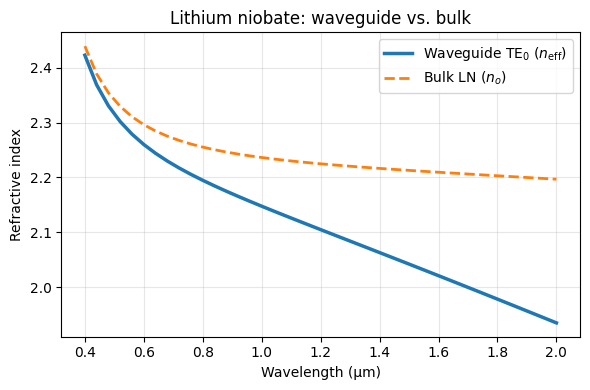

In [8]:
import numpy as np
import matplotlib.pyplot as plt
data = np.loadtxt('ln_neff_vs_bulk.csv',
           delimiter=',',
           skiprows=1)

wavelengths = data[:,0]
n_eff = data[:,1]
n_o= data[:,2]
n_e = data[:,3]         

fig, ax = plt.subplots(figsize=(6, 4))

ax.plot(
    wavelengths, n_eff,
    linewidth=2.5,
    label=r"Waveguide TE$_0$ ($n_\mathrm{eff}$)"
)
ax.plot(
    wavelengths, n_o, "--",
    linewidth=2,
    label=r"Bulk LN ($n_o$)"
)
# ax.plot(
    # wavelengths, n_e, ":",
    # linewidth=2,
    # label=r"Bulk LN ($n_e$)"
# )

ax.set_xlabel("Wavelength (µm)")
ax.set_ylabel("Refractive index")
ax.set_title("Lithium niobate: waveguide vs. bulk")
ax.grid(alpha=0.3)
ax.legend()
fig.tight_layout()
fig.savefig("ln_neff_vs_bulk.png", dpi=300)

plt.show()
